In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("geyser")


In [3]:
df.shape

(272, 3)

In [4]:
df.columns

Index(['duration', 'waiting', 'kind'], dtype='object')

In [5]:
df.head()

,duration,waiting,kind
0,3.600,79,long
1,1.800,54,short
2,3.333,74,long
3,2.283,62,short
4,4.533,85,long


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 272 entries, 0 to 271
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   duration  272 non-null    float64
 1   waiting   272 non-null    int64  
 2   kind      272 non-null    object 
dtypes: float64(1), int64(1), object(1)
memory usage: 6.5+ KB


In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.describe()

,duration,waiting
count,272.000000,272.000000
mean,3.487783,70.897059
std,1.141371,13.594974
min,1.600000,43.000000
25%,2.162750,58.000000
50%,4.000000,76.000000
75%,4.454250,82.000000
max,5.100000,96.000000


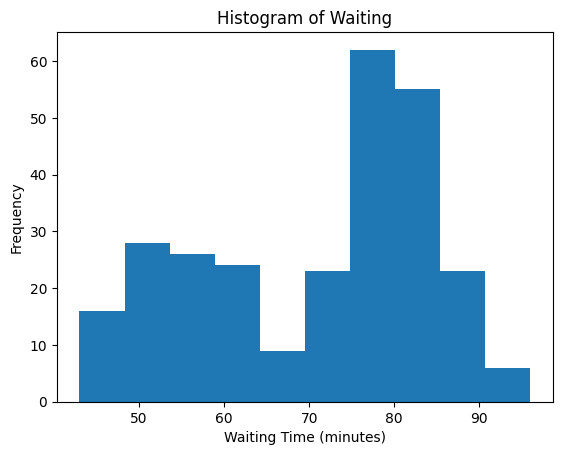

In [12]:
plt.hist(df["waiting"])
plt.xlabel("Waiting Time (minutes)")
plt.ylabel("Frequency")
plt.title("Histogram of Waiting")
plt.show()

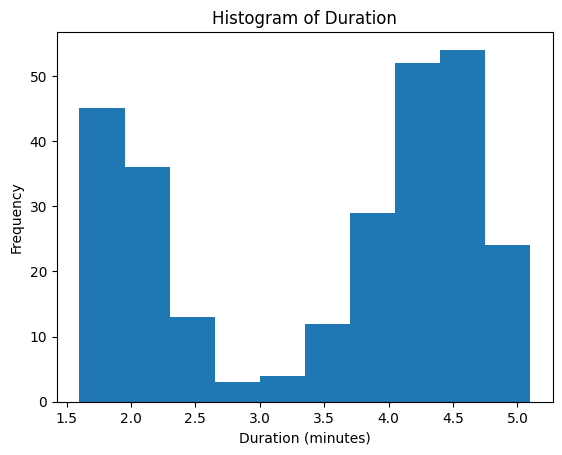

In [13]:
plt.hist(df["duration"])
plt.xlabel("Duration (minutes)")
plt.ylabel("Frequency")
plt.title("Histogram of Duration")
plt.show()

Do longer eruptions tend to be followed by longer waiting times?

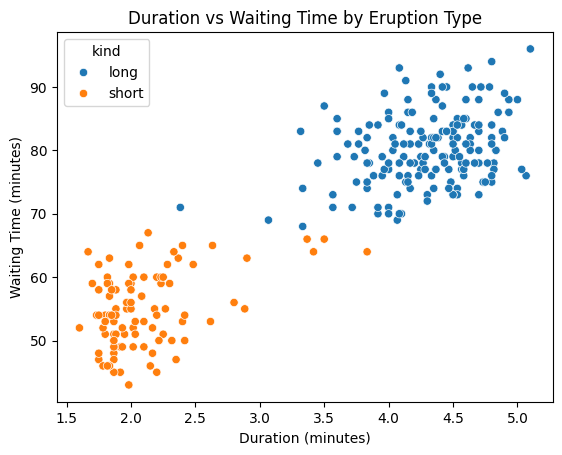

In [17]:
sns.scatterplot(
    data=df,
    x="duration",
    y="waiting",
    hue="kind"
)

plt.xlabel("Duration (minutes)")
plt.ylabel("Waiting Time (minutes)")
plt.title("Duration vs Waiting Time by Eruption Type")
plt.show()

##Findings:
Bimodal distributions: Eruption durations and waiting times appear to form two groups.

Positive relationship: Longer eruptions tend to be associated with longer waiting times.



Distinct clusters: Colouring the scatter plot by kind reveals clear separation between short and long eruptions.



Limited overlap: The two eruption types occupy largely different regions of the plot.

In [19]:
(df["duration"]).corr(df["waiting"])

np.float64(0.9008111683218127)

In [20]:
df['kind'].value_counts()

,count
kind,
long,172
short,100


##which kind of eruption has higher average waiting time?

In [21]:
df.groupby('kind')['waiting'].mean()

,waiting
kind,
long,80.284884
short,54.750000


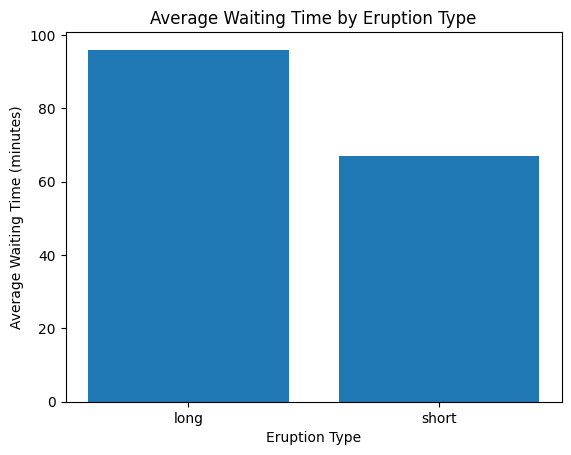

In [22]:
plt.bar(df['kind'], df['waiting'])
plt.xlabel('Eruption Type')
plt.ylabel('Average Waiting Time (minutes)')
plt.title('Average Waiting Time by Eruption Type')
plt.show()

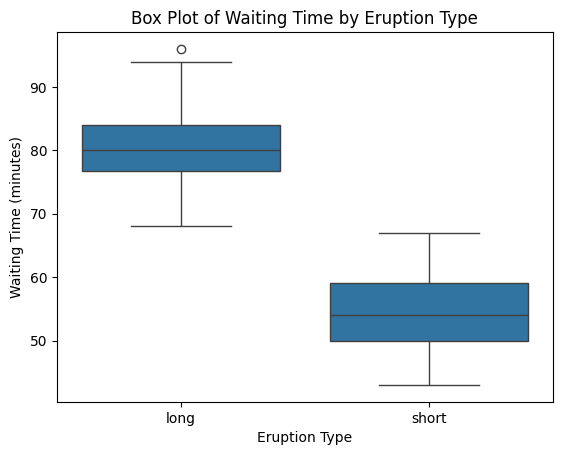

In [23]:
sns.boxplot(data=df, x='kind', y='waiting')
plt.xlabel('Eruption Type')
plt.ylabel('Waiting Time (minutes)')
plt.title('Box Plot of Waiting Time by Eruption Type')
plt.show()

Higher median: Long eruptions
wider spread: short eruptions
one potential outlier

In [30]:
long_waiting = df.loc[df['kind'] == 'long', 'waiting']

Q1 = long_waiting.quantile(0.25)
Q3 = long_waiting.quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper bound:", upper_bound)
outlier = df[(df['kind'] == 'long') & ((df['waiting'] < lower_bound) | (df['waiting'] > upper_bound))]
outlier

Q1: 76.75
Q3: 84.0
IQR: 7.25
Upper bound: 94.875


,duration,waiting,kind
148,5.1,96,long


In [32]:
df.groupby('kind')[['duration', 'waiting']].corr()

duration   waiting
kind                              
long  duration  1.000000  0.322703
      waiting   0.322703  1.000000
short duration  1.000000  0.427808
      waiting   0.427808  1.000000

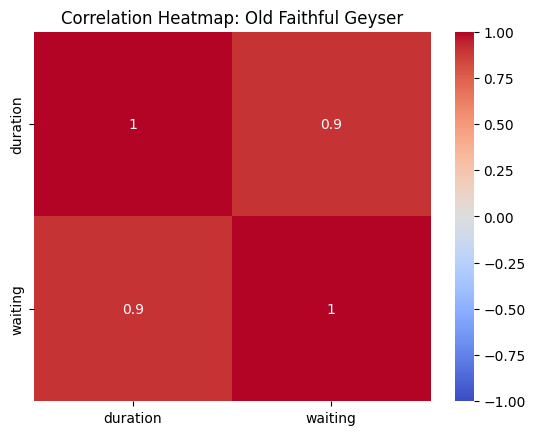

In [34]:
corr = df[['duration', 'waiting']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)

plt.title('Correlation Heatmap: Old Faithful Geyser')
plt.show()


### Key Findings

- Eruption duration and waiting time show two distinct clusters.
- Overall correlation is strongly positive ( 0.90).
- Long eruptions have a higher mean waiting time (80.28 min) than short eruptions (54.75 min).
- Within-group correlations are weaker than the overall correlation.
- The IQR method flagged a potential outlier at 96 minutes in the long-eruption group.